# QFF 2026 · Phase 2 · QML track — PS-Q1 (ECG heartbeat classification) + Task A + Task B

**Selected problem statement: PS-Q1** (same PS as Phase 1) · **Common tasks: Task A (Bell state) and Task B (Processor D)**
Noise model for every noisy number: organiser `QFF2026-v2` (`noise_model/benchmark_noise_model.py`, unchanged, circuits transpiled to the fully-noised basis `rx, ry, rz, cx`).

Run from the repository root: `jupyter nbconvert --to notebook --execute --inplace solution.ipynb`
(runtime: roughly 10-20 minutes on a laptop; all seeds fixed).

**Honest framing up front.** The hidden-test baseline for this dataset is a plain logistic regression with macro-F1 = 1.000, so the data is
(almost) linearly separable. A quantum model cannot beat that; the interesting questions are *how small a circuit suffices*, *what the
entanglement and the encoding actually contribute* (ablations) and *how much of the margin survives realistic noise*. The notebook is built around those questions.

In [1]:
import os, sys, json, time, platform, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath(os.getcwd())
assert os.path.exists(os.path.join(ROOT, "noise_model", "benchmark_noise_model.py")), "Run this notebook from the repository root."
sys.path.insert(0, ROOT)
os.makedirs("results/figures", exist_ok=True)

import qiskit, qiskit_aer, sklearn
from vqc.qiskit_bridge import (build_circuit, ideal_expectations, noisy_expectations,
                               readout_calibration, compile_stats)   # also puts noise_model/, benchmark/, tools/ on sys.path
from vqc.model import CircuitSpec, FeaturePipeline, VQC, build_ops, circuit_stats
from vqc.metrics import macro_f1, bootstrap_ci, paired_bootstrap_diff, summary
from vqc import experiments as ex, classical, processor as P, report, outputs, diagram
from benchmark_noise_model import get_noise_params, VERSION
from validate_predictions import validate

SEED = 42
np.random.seed(SEED)
TEAM_NAME = "Nova"      # <- edit before submitting (used in results.md)
RUN_SWEEPS = False                # True: regenerate results/model_selection.csv and ablation.csv here (~25 min)
SHOTS = 4096                      # shots per circuit for every noisy / shot-based evaluation of the classifier

R = {"team": TEAM_NAME, "seed": SEED, "shots": SHOTS, "noise_params": get_noise_params(),
     "versions": {"python": platform.python_version(), "qiskit": qiskit.__version__, "qiskit-aer": qiskit_aer.__version__,
                  "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__}}
print(R["versions"]); print("noise model:", VERSION, get_noise_params()["single_qubit_depolarizing"],
      get_noise_params()["two_qubit_depolarizing"], get_noise_params()["readout_error"])

{'python': '3.12.10', 'qiskit': '2.3.0', 'qiskit-aer': '0.17.2', 'scikit-learn': '1.9.1', 'numpy': '2.4.6', 'pandas': '3.1.0'}
noise model: QFF2026-v2 0.01 0.05 0.02


## 1. Data and the classical reference point

30 features = 5 windows × 6 statistics. Everything below (scaler, PCA, angle map, classical hyper-parameters, circuit choice) is **fitted on `ecg_train.csv` only**;
`ecg_val.csv` is used for model selection only; `ecg_test_features.csv` is only ever passed through the already-fitted model.

In [2]:
tr = pd.read_csv("data/q1/ecg_train.csv"); va = pd.read_csv("data/q1/ecg_val.csv"); te = pd.read_csv("data/q1/ecg_test_features.csv")
FEATURES = [c for c in tr.columns if c != "label"]
assert list(te.columns) == ["sample_id"] + FEATURES and list(va.columns) == list(tr.columns)
Xtr, ytr = tr[FEATURES].to_numpy(), tr["label"].to_numpy()
Xva, yva = va[FEATURES].to_numpy(), va["label"].to_numpy()
Xte = te[FEATURES].to_numpy()
print("train", Xtr.shape, "val", Xva.shape, "test", Xte.shape, "| P(arrhythmia): train %.3f, val %.3f" % (ytr.mean(), yva.mean()))
from sklearn.feature_selection import f_classif
Fstat, _ = f_classif((Xtr - Xtr.mean(0)) / Xtr.std(0), ytr)
top = pd.Series(Fstat, index=FEATURES).sort_values(ascending=False).head(5)
print("ANOVA F of the 5 most informative features (train):"); print(top.round(0).to_string())

train (6000, 30) val (1500, 30) test (1500, 30) | P(arrhythmia): train 0.397, val 0.401
ANOVA F of the 5 most informative features (train):
w5_mean    130598.0
w5_max      41971.0
w3_kurt     28706.0
w5_std      20413.0
w4_std      17229.0


## 2. Quantum design and how it was selected (validation data only)

**Design space** (decided before looking at any result): all circuits use the same skeleton
`angle-encode → trainable RY·RZ per qubit → ring of CX → ⟨Z-string⟩ → logit = w·⟨Z⟩ + b`, with `w, b` trained jointly (hybrid read-out).
Swept: qubits ∈ {3, 4}, layers ∈ {1, 2}, feature reduction ∈ {PCA, ANOVA top-k} (both fitted on train), read-out ∈ {Z on qubit 0, parity of all qubits}, 3 seeds each.

**Selection rule (fixed in advance):** take the best mean validation macro-F1; among all configurations within 0.0015 of it
(≈ 2 of 1,500 validation beats, i.e. statistically indistinguishable) choose the one with the **fewest two-qubit gates**, then fewest qubits.
Rationale: under the organiser noise model each CX costs 5 % depolarisation, each 1-qubit gate 1 %, so for equal accuracy the cheapest circuit is the most noise-robust one.

In [3]:
if RUN_SWEEPS:
    sel = ex.run_tasks(ex.selection_tasks((Xtr, ytr, Xva, yva)), n_jobs=1); sel.to_csv("results/model_selection.csv", index=False)
else:
    sel = pd.read_csv("results/model_selection.csv")
best, table = ex.pick_final(sel)
print(table.round(4).to_string(index=False))
print("\nSELECTED:", dict(best))
FINAL = dict(n_qubits=int(best["qubits_cfg"]), n_layers=int(best["layers"]), reducer=str(best["reducer"]),
             readout="all" if best["readout"] == "Z-all" else "Z0")
spec = CircuitSpec(n_qubits=FINAL["n_qubits"], n_layers=FINAL["n_layers"], entangler="ring",
                   readout=tuple(range(FINAL["n_qubits"])) if FINAL["readout"] == "all" else (0,))
ops, n_params = build_ops(spec)
R["final"] = FINAL; R["selection_table"] = table; R["logical_stats"] = circuit_stats(ops)
print(spec); print("logical circuit:", R["logical_stats"])

 qubits_cfg  layers reducer readout    val  val_sd  noisy  cx  depth
          3       2     pca      Z0 1.0000  0.0000 1.0000   6     12
          3       2   anova   Z-all 1.0000  0.0000 1.0000   6     12
          4       1     pca   Z-all 1.0000  0.0000 1.0000   4      7
          3       2   anova      Z0 0.9998  0.0004 0.9993   6     12
          4       2   anova      Z0 0.9995  0.0004 0.9986   8     14
          4       2     pca   Z-all 0.9988  0.0008 0.9778   8     14
          3       2     pca   Z-all 0.9979  0.0000 1.0000   6     12
          4       2     pca      Z0 0.9975  0.0011 0.9872   8     14
          3       1   anova      Z0 0.9975  0.0011 0.9946   3      6
          4       2   anova   Z-all 0.9975  0.0014 0.9973   8     14
          3       1   anova   Z-all 0.9972  0.0000 0.9959   3      6
          3       1     pca      Z0 0.9940  0.0004 0.9544   3      6
          4       1   anova   Z-all 0.9935  0.0058 0.9946   4      7
          4       1   anova      Z

## 3. Training the final model (ideal simulation, parameter-shift gradients, 3 seeds)

The circuit is simulated with an exact NumPy state-vector simulator (verified against Qiskit's `Statevector` in Section 4) so that 6,000 training samples × parameter-shift gradients stay fast.
Loss: class-weighted binary cross-entropy (mild 60/40 imbalance), Adam, mini-batches. The seed with the best **validation** macro-F1 is kept; the other seeds give the spread.

seed 0 val macro-F1 1.0000 train 22 s
seed 1 val macro-F1 1.0000 train 26 s
seed 2 val macro-F1 1.0000 train 33 s


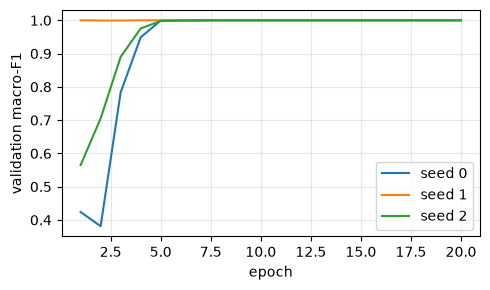

In [4]:
runs = []
for s in (0, 1, 2):
    fp_s = FeaturePipeline(spec.n_features, FINAL["reducer"], s).fit(Xtr, ytr)      # fitted on train only
    A_s, Av_s = fp_s.transform(Xtr), fp_s.transform(Xva)
    m = VQC(spec, s); m.fit(A_s, ytr, Av_s, yva, epochs=ex.EPOCHS, batch=ex.BATCH, lr=ex.LR)
    runs.append(dict(seed=s, fp=fp_s, model=m, val_f1=macro_f1(yva, m.predict(Av_s))))
    print("seed", s, "val macro-F1 %.4f" % runs[-1]["val_f1"], "train %.0f s" % m.result.seconds)
best_run = max(runs, key=lambda r: (r["val_f1"], -r["seed"]))
fp, model = best_run["fp"], best_run["model"]
theta, w, b = model.result.theta, model.result.w, model.result.b
A, Av, At = fp.transform(Xtr), fp.transform(Xva), fp.transform(Xte)
R["seeds"] = [dict(seed=r["seed"], val_macro_f1=r["val_f1"], train_seconds=r["model"].result.seconds) for r in runs]
R["chosen_seed"] = best_run["seed"]
fig, ax = plt.subplots(figsize=(5, 3))
for r in runs: ax.plot([h["epoch"] for h in r["model"].result.history], [h["val_macro_f1"] for h in r["model"].result.history], label=f"seed {r['seed']}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1"); ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig("results/figures/training_curves.png", dpi=150); plt.show()

## 4. Cross-check: NumPy simulator vs Qiskit `Statevector`, then ideal results

The same op list is turned into a Qiskit circuit; the exact expectation values must agree to machine precision.

max |NumPy - Qiskit Statevector| over 25 samples: 2.78e-16
IDEAL (exact)  validation macro-F1 1.0000  95% CI [1.0000, 1.0000]  accuracy 1.0000
seeds (val macro-F1): mean 1.0000 sd 0.0000
predictions_q1.csv validator: OK | predicted Arrhythmia share: 0.410


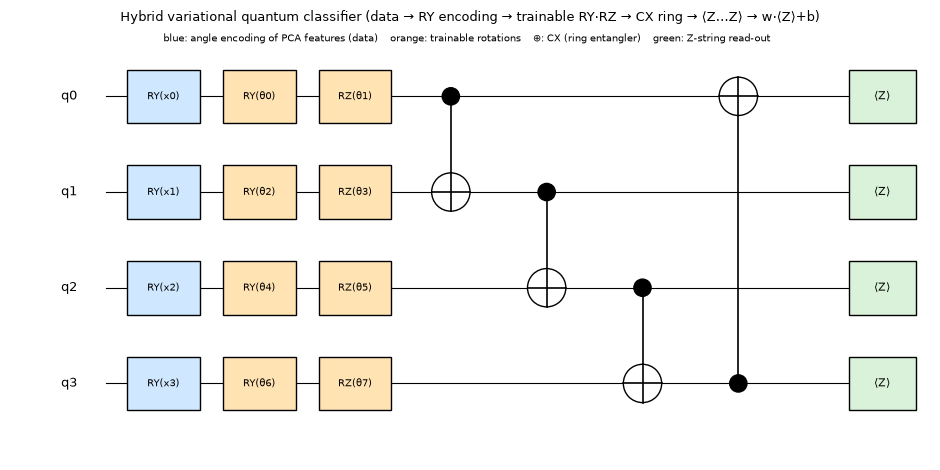

results/test_samples_with_predictions.csv: (1500, 35) | predicted Normal 885, Arrhythmia 615
sample_id  predicted_label predicted_class  p_arrhythmia
       s0                0          Normal      0.027399
       s1                1      Arrhythmia      0.997159
       s2                1      Arrhythmia      0.990168
       s3                1      Arrhythmia      0.999700
       s4                0          Normal      0.021294


In [5]:
n, nf = spec.n_qubits, spec.n_features
idx = np.arange(0, len(Av), 60)
f_np = model.expectation(Av[idx], theta)
f_qk = ideal_expectations(ops, n, nf, n_params, spec.readout, Av[idx], theta)
print("max |NumPy - Qiskit Statevector| over %d samples: %.2e" % (len(idx), np.abs(f_np - f_qk).max()))
assert np.abs(f_np - f_qk).max() < 1e-8, "simulator and Qiskit disagree"

f_va, f_te = model.expectation(Av, theta), model.expectation(At, theta)
logit_va, logit_te = w * f_va + b, w * f_te + b
pred_va, pred_te = (logit_va > 0).astype(int), (logit_te > 0).astype(int)
ideal_val = summary(yva, pred_va)
print("IDEAL (exact)  validation macro-F1 %.4f  95%% CI [%.4f, %.4f]  accuracy %.4f" % (ideal_val["macro_f1"], *ideal_val["ci95"], ideal_val["accuracy"]))
print("seeds (val macro-F1): mean %.4f sd %.4f" % (np.mean([r["val_f1"] for r in runs]), np.std([r["val_f1"] for r in runs], ddof=1)))

pd.DataFrame({"sample_id": te["sample_id"], "label": pred_te}).to_csv("predictions_q1.csv", index=False)
print("predictions_q1.csv validator:", validate("q1", "predictions_q1.csv") or "OK", "| predicted Arrhythmia share: %.3f" % pred_te.mean())
R["ideal_val"] = ideal_val

# ---- architecture figure (drawn from the exact op list that was trained) and per-sample test copy
diagram.draw_vqc(ops, n, spec.readout, theta, "results/figures/vqc_architecture.png"); plt.show()
test_copy = outputs.write_test_copy(te, pred_te, logit_te, "results/test_samples_with_predictions.csv")
print("results/test_samples_with_predictions.csv:", test_copy.shape, "| predicted Normal %d, Arrhythmia %d" % tuple(np.bincount(pred_te, minlength=2)))
print(test_copy[["sample_id", "predicted_label", "predicted_class", "p_arrhythmia"]].head(5).to_string(index=False))

## 5. Classical baselines (same data, same protocol)

Fitted on train, small hyper-parameter grids scored on validation only. The last row feeds the classical model the *same low-dimensional inputs as the circuit* — the fairest like-for-like comparison.

In [ ]:
base = classical.run_baselines(Xtr, ytr, Xva, yva, seed=SEED, reduced=(fp.reduce(Xtr), fp.reduce(Xva)))
rows = []
for name, d in base.items():
    pv = d["model"].predict(d["inputs"][1])
    lo, hi = bootstrap_ci(yva, pv)
    rows.append(dict(model=name, val_macro_f1=d["val_macro_f1"], ci_lo=lo, ci_hi=hi, params=str(d["params"])))
baseline_df = pd.DataFrame(rows); print(baseline_df.round(4).to_string(index=False))
R["baselines"] = baseline_df

# ---- accuracy / precision / recall / F1 for every model on the labelled splits (test labels are hidden)
rows = {"VQC (ideal) - train": (ytr, (w * model.expectation(A, theta) + b > 0).astype(int)), "VQC (ideal) - validation": (yva, pred_va)}
for name, d in base.items():
    rows[name + " - train"] = (ytr, d["model"].predict(d["inputs"][0])); rows[name + " - validation"] = (yva, d["model"].predict(d["inputs"][1]))
metrics_df = outputs.metrics_table(rows)
metrics_df.to_csv("results/metrics_summary.csv", index=False); R["metrics_table"] = metrics_df
print(metrics_df[["model / split", "n", "accuracy", "precision_abnormal", "recall_abnormal", "f1_abnormal", "f1_macro"]].round(4).to_string(index=False))

## 6. Noisy evaluation under the organiser model QFF2026-v2

`noisy_expectations()` transpiles the circuit with `prepare_for_noisy_run()` (basis `rx, ry, rz, cx`, optimisation level 1, seed 42, raises if any un-noised gate remains), then runs Aer with the benchmark noise model, 4,096 shots per sample.
The **trained, unchanged** parameters and the deployed read-out `w, b` are used ("as deployed"). Test labels are not available, so on the test set we report how many predictions the noise changes.

In [ ]:
t0 = time.time()
fn_va, se_va, tqc = noisy_expectations(ops, n, nf, n_params, spec.readout, Av, theta, shots=SHOTS)
fn_te, _, _ = noisy_expectations(ops, n, nf, n_params, spec.readout, At, theta, shots=SHOTS)
fs_va, _, _ = noisy_expectations(ops, n, nf, n_params, spec.readout, Av, theta, shots=SHOTS, ideal=True)   # noise-free, same shots
print("noisy runs: %.0f s" % (time.time() - t0)); R["compiled_stats"] = compile_stats(tqc); print("compiled (rx,ry,rz,cx):", R["compiled_stats"])

pn_va, pn_te = (w * fn_va + b > 0).astype(int), (w * fn_te + b > 0).astype(int)
ps_va = (w * fs_va + b > 0).astype(int)
noisy_val, shot_ideal_val = summary(yva, pn_va), summary(yva, ps_va)
d_lo, d_hi = paired_bootstrap_diff(yva, ps_va, pn_va)
agree_te = float((pn_te == pred_te).mean())
print("ideal, exact           : macro-F1 %.4f" % ideal_val["macro_f1"])
print("ideal, %d shots        : macro-F1 %.4f  CI [%.4f, %.4f]" % (SHOTS, shot_ideal_val["macro_f1"], *shot_ideal_val["ci95"]))
print("NOISY (QFF2026-v2)     : macro-F1 %.4f  CI [%.4f, %.4f]  accuracy %.4f" % (noisy_val["macro_f1"], *noisy_val["ci95"], noisy_val["accuracy"]))
print("paired CI of (ideal-shots minus noisy) macro-F1: [%.4f, %.4f]" % (d_lo, d_hi))
print("test: noisy predictions equal ideal predictions for %.2f%% of 1500 samples" % (100 * agree_te))
print("confusion (rows=true, cols=pred) ideal:", ideal_val["confusion"], " noisy:", noisy_val["confusion"])
R.update(noisy_val=noisy_val, shot_ideal_val=shot_ideal_val, paired_diff=(d_lo, d_hi), test_agreement=agree_te)
pd.DataFrame({"sample_id": te["sample_id"], "label": pn_te}).to_csv("results/predictions_q1_noisy_asdeployed.csv", index=False)
test_copy = outputs.write_test_copy(te, pred_te, logit_te, "results/test_samples_with_predictions.csv",
                                    extra={"predicted_label_noisy": pn_te, "p_arrhythmia_noisy": outputs.sigmoid(w * fn_te + b)})
noisy_metrics = outputs.metrics_table({"VQC (ideal, 4096 shots) - validation": (yva, ps_va), "VQC (noisy QFF2026-v2) - validation": (yva, pn_va)})
noisy_metrics.to_csv("results/metrics_noisy.csv", index=False); R["metrics_noisy"] = noisy_metrics
print(noisy_metrics[["model / split", "accuracy", "precision_abnormal", "recall_abnormal", "f1_abnormal", "f1_macro"]].round(4).to_string(index=False))

### Why noise changes (or does not change) macro-F1

Depolarising noise after every gate and symmetric read-out flips contract every Pauli expectation towards 0. The decision rule `w·⟨Z⟩ + b > 0` was trained for the *un-contracted* ⟨Z⟩, so noise (i) shrinks the margin
and (ii) moves the effective threshold if the learned bias is not zero. Below we measure the contraction factor, check which samples flip and whether they sit near the boundary.

In [ ]:
slope, icpt = np.polyfit(fs_va, fn_va, 1)
corr = np.corrcoef(fs_va, fn_va)[0, 1]
flipped = pn_va != ps_va
margin = np.abs(w * fs_va + b)
print("noisy <Z-string> ~= %.3f * ideal %+.3f   (corr %.4f)" % (slope, icpt, corr))
print("expected read-out-only factor (1-2*0.02)^%d = %.3f" % (len(spec.readout), (1 - 2 * 0.02) ** len(spec.readout)))
print("flipped decisions: %d of %d | median |logit| flipped %.2f vs all %.2f" % (flipped.sum(), len(yva), np.median(margin[flipped]) if flipped.any() else float('nan'), np.median(margin)))
thr_ideal = -b / w
print("decision threshold on <Z>: ideal %.3f -> after contraction the same boundary sits at %.3f" % (thr_ideal, slope * thr_ideal + icpt))
for c in (0, 1):
    m_ = yva == c
    print("class %d: recall ideal-shots %.4f  noisy %.4f" % (c, (ps_va[m_] == c).mean(), (pn_va[m_] == c).mean()))
R["noise_analysis"] = dict(slope=float(slope), intercept=float(icpt), corr=float(corr), flipped=int(flipped.sum()),
                           median_margin_flipped=float(np.median(margin[flipped])) if flipped.any() else None,
                           median_margin_all=float(np.median(margin)), thr_ideal=float(thr_ideal),
                           recall_ideal={c: float((ps_va[yva == c] == c).mean()) for c in (0, 1)},
                           recall_noisy={c: float((pn_va[yva == c] == c).mean()) for c in (0, 1)})
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for c, col in ((0, "tab:blue"), (1, "tab:red")):
    ax[0].hist(f_va[yva == c], bins=40, alpha=.5, color=col, label=f"class {c} ideal")
    ax[0].hist(fn_va[yva == c], bins=40, alpha=.5, color=col, histtype="step", lw=2, label=f"class {c} noisy")
ax[0].axvline(thr_ideal, color="k", ls="--", lw=1); ax[0].set_xlabel("<Z-string>"); ax[0].legend(fontsize=7); ax[0].set_title("read-out distribution (validation)")
ax[1].scatter(fs_va, fn_va, s=3, alpha=.4); xs = np.linspace(-1, 1, 3); ax[1].plot(xs, slope * xs + icpt, "r"); ax[1].plot(xs, xs, "k:", lw=1)
ax[1].set_xlabel("ideal"); ax[1].set_ylabel("noisy"); ax[1].set_title("contraction by noise"); fig.tight_layout()
fig.savefig("results/figures/noise_effect.png", dpi=150); plt.show()

### Optional: three cheap mitigation / calibration steps (PS-Q1 does not require mitigation)

* **Read-out error mitigation (REM):** two calibration circuits per measured qubit estimate the flip rate; ⟨Z-string⟩ is divided by Π(1 − 2p̂). Overhead: 2·|read-out qubits| circuits.
* **Threshold re-calibration:** refit only the 2 classical numbers `(w, b)` on *noisy validation outputs* (5-fold cross-validated on validation, no test data). Overhead: none at inference.
* **Zero-noise extrapolation (ZNE):** global unitary folding U(U†U)^k with scale factors 1, 3, 5 and Richardson extrapolation to zero noise, on the first 600 validation samples. Overhead: (1+3+5)× the gates, 3× the circuits.

In [ ]:
mit = []
def add(name, f1, extra_circuits, note): mit.append(dict(strategy=name, val_macro_f1=f1, extra_circuits=extra_circuits, note=note))
add("none (as deployed)", noisy_val["macro_f1"], 0, "reference")
try:
    rates = readout_calibration(n, spec.readout)
    c = float(np.prod([1 - 2 * p01 for p01, _ in rates]))
    f_rem = np.clip(fn_va / c, -1, 1)
    add("read-out mitigation (REM)", macro_f1(yva, (w * f_rem + b > 0).astype(int)), 2 * len(spec.readout), "estimated flip rates %s, correction factor %.3f" % ([round(r[0], 4) for r in rates], c))
except Exception as e:                                    # optional extra: never stop the notebook
    import traceback; traceback.print_exc(); print("REM skipped:", e)
try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import cross_val_predict, StratifiedKFold
    lr_cal = LogisticRegression(C=100.0, class_weight="balanced")
    p_cv = cross_val_predict(lr_cal, fn_va.reshape(-1, 1), yva, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    add("threshold re-calibration (w,b on noisy val, 5-fold CV)", macro_f1(yva, p_cv), 0, "classical post-processing only")
    lr_cal.fit(fn_va.reshape(-1, 1), yva); pn_te_cal = lr_cal.predict(fn_te.reshape(-1, 1))
    R["test_agreement_recal"] = float((pn_te_cal == pred_te).mean())
except Exception as e:
    import traceback; traceback.print_exc(); print("recalibration skipped:", e)
try:
    NZ = 600; scales = (1, 3, 5); fz = {}
    for sc in scales:
        fz[sc], _, _ = noisy_expectations(ops, n, nf, n_params, spec.readout, Av[:NZ], theta, shots=SHOTS, fold=sc)
    f_rich = np.clip((15 * fz[1] - 10 * fz[3] + 3 * fz[5]) / 8, -1, 1); f_lin = np.clip((3 * fz[1] - fz[3]) / 2, -1, 1)
    ref = macro_f1(yva[:NZ], pn_va[:NZ])
    add("ZNE, linear (scales 1,3) - first %d val" % NZ, macro_f1(yva[:NZ], (w * f_lin + b > 0).astype(int)), NZ * 2, "unmitigated on the same %d samples: %.4f" % (NZ, ref))
    add("ZNE, Richardson (scales 1,3,5) - first %d val" % NZ, macro_f1(yva[:NZ], (w * f_rich + b > 0).astype(int)), NZ * 3, "gates x(1+3+5); extrapolation amplifies shot noise")
except Exception as e:
    import traceback; traceback.print_exc(); print("ZNE skipped:", e)
mit_df = pd.DataFrame(mit); print(mit_df.round(4).to_string(index=False)); R["mitigation"] = mit_df

## 7. Ablation studies (validation macro-F1, 3 seeds; `dev-noisy` = exact density-matrix replica of the noise model, first 500 validation samples)

One factor at a time around the final design. These runs use the NumPy simulators for speed (`results/ablation.csv`, regenerated by `scripts/run_sweeps.py`); the official Aer numbers are those in Section 6.

In [ ]:
if RUN_SWEEPS:
    base_spec = dict(n_qubits=spec.n_qubits, n_layers=spec.n_layers, entangler="ring", readout=FINAL["readout"])
    abl = ex.run_tasks(ex.ablation_tasks(base_spec, FINAL["reducer"], (Xtr, ytr, Xva, yva)), n_jobs=1); abl.to_csv("results/ablation.csv", index=False)
else:
    abl = pd.read_csv("results/ablation.csv")
abl_s = abl.groupby("variant", sort=False).agg(val_mean=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
        dev_noisy_mean=("dev_noisy_val_macro_f1", "mean"), two_qubit_gates=("two_qubit_gates", "first"), depth=("depth", "first"), params=("trainable_gates", "first")).reset_index()
print(abl_s.round(4).to_string(index=False)); R["ablation"] = abl_s
fig, ax = plt.subplots(figsize=(7, 3.6)); yy = np.arange(len(abl_s))
ax.barh(yy - .2, abl_s["val_mean"], .4, xerr=abl_s["val_sd"].fillna(0), label="ideal"); ax.barh(yy + .2, abl_s["dev_noisy_mean"], .4, label="dev-noisy")
ax.set_yticks(yy); ax.set_yticklabels(abl_s["variant"], fontsize=7); ax.set_xlim(max(0.85, abl_s[["val_mean", "dev_noisy_mean"]].min().min() - .02), 1.002); ax.invert_yaxis(); ax.legend(fontsize=7); ax.set_xlabel("validation macro-F1")
fig.tight_layout(); fig.savefig("results/figures/ablation.png", dpi=150); plt.show()

## 8. Task A — Bell state |Φ⁺⟩

Official `task_a_bell()` (8,192 shots per basis; **F = (1 + ⟨XX⟩ − ⟨YY⟩ + ⟨ZZ⟩)/4**; ⟨P⟩ = (N_even − N_odd)/N). P(00)+P(11) is *not* used.

In [ ]:
from qff_qml_benchmark import task_a_bell
task_a = task_a_bell(); R["task_a"] = task_a
for cond in ("ideal", "noisy"):
    r = task_a[cond]
    print("%-5s XX=%+.4f±%.4f  YY=%+.4f±%.4f  ZZ=%+.4f±%.4f   F=%.4f±%.4f" % (cond, r["XX"], r["XX_se"], r["YY"], r["YY_se"], r["ZZ"], r["ZZ_se"], r["fidelity"], r["fidelity_se"]))
json.dump(task_a, open("results/task_a.json", "w"), indent=2)
Fi, Fn = task_a["ideal"]["fidelity"], task_a["noisy"]["fidelity"]
R["task_a_text"] = report.task_a_text(task_a)
print(); print(R["task_a_text"])

## 9. Task B — Processor D

**Design principle.** The processor is designed around *our* circuit (4-qubit ring of CX, 1-qubit RY/RZ rotations) and the mandatory QFT-3 benchmark (needs a 3-qubit all-to-all triangle and a final SWAP).
Candidate topologies and gate sets are fixed in `vqc/processor.py` **before** looking at numbers; the choice is made by a coded rule on the official benchmark:

1. eligible = valid design, our compiled circuit needs **0 routing SWAPs** (native 4-cycle) and the gate set natively contains `ry, rz, cx`;
2. choose the topology with the highest **noisy QFT-3 fidelity** (official `task_b_qft3`), tie → fewer qubits → fewer two-qubit gates;
3. on that topology, repeat the comparison over the candidate gate sets.

One-way ("directed") links and the Phase-1 processors A/B are included on purpose, to show what link direction and an unsuitable topology cost.

In [ ]:
from qiskit import QuantumCircuit
qc_unbound, xs_, ts_ = build_circuit(ops, n, nf, n_params, spec.readout, measure=False)
vqc_logical = qc_unbound.assign_parameters({**dict(zip(xs_, Av[0])), **dict(zip(ts_, theta))})
print("our circuit, logical: depth %d, two-qubit gates %d" % (vqc_logical.depth(), sum(1 for i in vqc_logical.data if i.operation.num_qubits == 2)))

rows = []
for topo in P.TOPOLOGIES:
    cfg = P.make_config("cand", topo, "rx,ry,rz,cx")
    ev = P.evaluate(cfg, vqc_logical)
    rows.append(dict(topology=topo, gate_set="rx,ry,rz,cx", **{k: v for k, v in ev.items() if k != "problems"}))
topo_df = pd.DataFrame(rows)
show = ["topology", "valid", "qft3_circuit_depth_after_transpile", "qft3_two_qubit_gate_count", "qft3_swap_overhead", "qft3_fidelity_noisy", "vqc_depth", "vqc_two_qubit_gates", "vqc_swaps"]
print(topo_df[show].round(4).to_string(index=False))

In [ ]:
def eligible(df, gate_set_names=None):
    ok = df[(df["valid"]) & (df["vqc_swaps"] == 0)].copy()
    if "native" in ok: ok = ok[ok["native"].apply(lambda g: {"ry", "rz", "cx"} <= set(g))]
    return ok.sort_values(["qft3_fidelity_noisy", "n_qubits", "qft3_two_qubit_gate_count"], ascending=[False, True, True])

topo_df["n_qubits"] = [P.TOPOLOGIES[t][0] for t in topo_df["topology"]]
topo_df["native"] = [P.GATESETS["rx,ry,rz,cx"]] * len(topo_df)
best_topo = eligible(topo_df).iloc[0]["topology"]
print("selected topology:", best_topo)

rows = []
for gs in P.GATESETS:
    cfg = P.make_config("cand", best_topo, gs)
    ev = P.evaluate(cfg, vqc_logical)
    rows.append(dict(topology=best_topo, gate_set=gs, n_qubits=cfg["n_qubits"], native=cfg["native_gate_set"], **{k: v for k, v in ev.items() if k != "problems"}))
gs_df = pd.DataFrame(rows)
print(gs_df[["gate_set", "valid", "qft3_circuit_depth_after_transpile", "qft3_two_qubit_gate_count", "qft3_swap_overhead", "qft3_fidelity_noisy", "vqc_depth", "vqc_two_qubit_gates", "vqc_swaps"]].round(4).to_string(index=False))
best_gs = eligible(gs_df).iloc[0]["gate_set"]
print("selected gate set:", best_gs)
R["task_b_topologies"] = topo_df.drop(columns=["native"]); R["task_b_gatesets"] = gs_df.drop(columns=["native"])

In [ ]:
# ---- final Processor D config: written with the OFFICIAL benchmark_results, then re-validated
n_d, cmap_d, layout_d = P.TOPOLOGIES[best_topo]
cfg = P.make_config("QFF2026_PS-Q1_procD_v1", best_topo, best_gs)
final_row = gs_df[gs_df["gate_set"] == best_gs].iloc[0]
cfg["noise_assumptions"] = {
    "single_qubit_error_rate": 0.001, "two_qubit_error_rate": 0.01, "readout_error_rate": 0.02, "t1_us": 100, "t2_us": 80,
    "notes": ("Own assumption: a mature superconducting-style device (1q 0.1 %, 2q 1 %, readout 2 %, T1 100 us, T2 80 us). "
              "These values do NOT enter the Task B benchmark, which always applies the organiser model (1q 1 %, 2q 5 %, readout 2 %). "
              "At the organiser's 5x worse two-qubit error the design goal is fewest two-qubit gates, so SWAP-free routing matters most.")}
cfg["design_rationale"] = report.processor_rationale(best_topo, best_gs, final_row, topo_df, gs_df, R["compiled_stats"], R["logical_stats"])
cfg["benchmark_results"] = P.task_b_qft3(cfg)
P.save_config(cfg, "processor_d_config.json")
cfg_loaded = json.load(open("processor_d_config.json"))
problems = P.validate_processor_d(cfg_loaded)
assert not problems, problems
again = P.task_b_qft3(cfg_loaded)
assert all(cfg_loaded["benchmark_results"][k] == v for k, v in again.items()), "benchmark_results differ from a fresh official run"
print(json.dumps(cfg_loaded["benchmark_results"], indent=2)); print(cfg_loaded["design_rationale"])
R["processor_d"] = cfg_loaded
out = subprocess.run([sys.executable, "benchmark/qff_qml_benchmark.py", "processor_d_config.json"], capture_output=True, text=True)
print(out.stdout[-900:], out.stderr[-300:])
assert "WARNING" not in out.stdout, "official CLI reports a mismatch"

### Our classifier on Processor D (end-to-end, official noise model)

The same trained circuit is compiled to Processor D's directed coupling map and native gates (`prepare_for_noisy_run(..., coupling_map=..., basis_gates=...)`), then run under the organiser noise on 400 validation samples
and compared with the default all-to-all `rx, ry, rz, cx` compilation of Section 6 on the same samples.

In [ ]:
try:
    from qiskit.transpiler import CouplingMap
    NV = 400
    cm_d = CouplingMap([list(e) for e in cfg_loaded["coupling_map"]])
    fd, _, tqc_d = noisy_expectations(ops, n, nf, n_params, spec.readout, Av[:NV], theta, shots=SHOTS, coupling_map=cm_d, basis_gates=cfg_loaded["native_gate_set"])
    pd_ = (w * fd + b > 0).astype(int)
    R["vqc_on_D"] = dict(macro_f1=macro_f1(yva[:NV], pd_), generic_macro_f1=macro_f1(yva[:NV], pn_va[:NV]), n=NV,
                         compiled=compile_stats(tqc_d), generic_compiled=R["compiled_stats"])
    print(R["vqc_on_D"])
except Exception as e:
    import traceback; traceback.print_exc(); print("VQC-on-D end-to-end run skipped:", e); R["vqc_on_D"] = None
fig, ax = plt.subplots(figsize=(7, 3.4)); t_ = topo_df.sort_values("qft3_fidelity_noisy")
ax.barh(t_["topology"], t_["qft3_fidelity_noisy"]); ax.set_xlabel("noisy QFT-3 fidelity (official benchmark)"); ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig("results/figures/processor_candidates.png", dpi=150); plt.show()

## 10. Resources, reproducibility, report

In [ ]:
trained = model.result
R["resources"] = dict(qubits=n, logical_depth=R["logical_stats"]["depth"], logical_two_qubit=R["logical_stats"]["two_qubit_gates"],
    compiled_depth=R["compiled_stats"]["depth"], compiled_two_qubit=R["compiled_stats"]["two_qubit_gates"],
    trainable_circuit_params=n_params, readout_params=2, train_seconds_chosen=trained.seconds,
    train_seconds_all=sum(r["model"].result.seconds for r in runs), train_circuit_evals_chosen=trained.circuit_evals,
    inference_circuits=int(len(Av) + len(At) + len(Av)), shots=SHOTS)
print(R["resources"])

freeze = subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
open("pip_freeze.txt", "w").write(freeze)
R["pip_freeze_filtered"] = "\n".join(l for l in freeze.splitlines() if any(k in l.lower() for k in ("pennylane", "qiskit", "scikit", "numpy", "pandas", "scipy", "matplotlib")))
report.write_results_md(R, "results.md"); report.update_readme_freeze("README.md", freeze)
print("wrote results.md, pip_freeze.txt, README pip-freeze block")
print(open("results.md").read()[:1500])